# 08 — Cara 2: Zero-GPU Mechanistic & Diagnostic Evidence Suite (`Ortho-Unified / GeoFiLM`)

**Tujuan:** Menyediakan paket bukti mekanistik & diagnostik **1-to-1 per sub-komponen `OrthoUnifiedBridge` (`O2`)** yang **100% berjalan di CPU Colab (0 menit GPU, 0 retraining)** langsung dari berkas evaluasi & log yang tersimpan di `geoflm2_new/data/`.

### Cakupan 6 Modul Audit:
1. **Modul 1 — Tangga Ablasi Makro Terpadu (`A0` $\rightarrow$ `M1–M4` $\rightarrow$ `U4` $\rightarrow$ `B1` $\rightarrow$ `O2` vs `Gautam 7B`):** Konsolidasi Dual-Judge, McNemar, 9-Grid, dan Green AI.
2. **Modul 2 — Bukti Gram-Schmidt (Ortogonalitas Eksak FP32):** Statistik distribusi `|cos_glob|` & `|cos_spat|` pada $N = 15,955$ sampel uji + stratifikasi L1/L2/L3.
3. **Modul 3 — Bukti Supervised Query-Aspect Router:** Menghitung **Precision, Recall, F1, Exact-Set Match, dan Non-Target Suppression Rate** dari `router_cats` (`ortho_diag.json`) terhadap ground-truth `question_class` *(metrik baru yang sebelumnya belum diekstrak)*.
4. **Modul 4 — Bukti 9D Moments + 2D Fourier Centroid (`O2` vs `B1`):** Analisis *Selective Geometric Gain* (Spatial/Geometric vs Non-Spatial heads) dan breakdown **9-Grid Spatial Grounding per kategori** (`abnormality_location`, `instrument_location`, `landmark_location`) untuk `O2_Raw`, `O2_Aligned`, `B1`, `M1–M4`, `U4`.
5. **Modul 5 — Perbaikan Bug Parser Ordinal `polyp_size` (`millimeters`/`mm`) & Audit CORN Head:** Memperbaiki bug regex `mm`-only di `07` yang membuat QWK jatuh ke `0.0`, serta membandingkan **CORN Head (`corn_size_tier`)** vs **Canon Head** vs **Teks Decoder (`O2_Raw`, `O2_Aligned`, `B1`, `M1–M4`)**.
6. **Modul 6 — Matriks Bukti 1-to-1 & Export Tabel LaTeX (`IEEEtran`):** Menyimpan seluruh CSV, Markdown, figure 300-DPI, dan potongan tabel LaTeX ke `geoflm2_new/data/cara2_mechanistic_audit/`.


In [2]:
# [C1] Install dependensi ringan CPU & mount Google Drive
!pip install -q datasets scikit-learn scipy pandas matplotlib seaborn

import os, sys, json, re, ast, math, warnings
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import cohen_kappa_score, precision_recall_fscore_support

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    IS_COLAB = True
except ImportError:
    IS_COLAB = False

# --- Auto-detect folder geoflm2_new ---
CANDIDATE_GEO_DIRS = [
    Path("/content/drive/MyDrive/geoflm2_new"),
    Path("/content/drive/My Drive/geoflm2_new"),
    Path(r"G:/My Drive/geoflm2_new"),
]
GEO_DIR = next((p for p in CANDIDATE_GEO_DIRS if p.exists()), None)
assert GEO_DIR is not None, f"Folder geoflm2_new tidak ditemukan! Cek mount Drive: {CANDIDATE_GEO_DIRS}"

KODE_DIR = GEO_DIR / "kode"
DATA_DIR = GEO_DIR / "data"
EXP_DIR  = DATA_DIR / "experiments"
OUT_DIR  = DATA_DIR / "cara2_mechanistic_audit"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Import helper kanonik dari kode/ortho_unified_core.py
if str(KODE_DIR) not in sys.path:
    sys.path.insert(0, str(KODE_DIR))
from ortho_unified_core import (
    as_list, atoms, as_class_list, aspect_pairs, CanonLabeler, POLYP_SIZE_ORDERED_TIERS
)

# --- Auto-detect Kvasir-VQA-x1 test split (Lokal Drive Arrow -> fallback HuggingFace) ---
CANDIDATE_TEST_DIRS = [
    Path("/content/drive/MyDrive/DOKTORAL/KvasirVQAX1/test"),
    Path("/content/drive/MyDrive/KvasirVQAX1/test"),
    Path(r"G:/.shortcut-targets-by-id/1jcCIrqYi6-IMNIk5Q1sS66o825iQoVVW/KvasirVQAX1/test"),
]
TEST_DS_DIR = next((p for p in CANDIDATE_TEST_DIRS if p.exists()), None)

from datasets import load_from_disk, load_dataset
if TEST_DS_DIR is not None:
    print(f"✓ Memuat test set dari lokal Drive: {TEST_DS_DIR}")
    ds = load_from_disk(str(TEST_DS_DIR))
else:
    print("⚠ Folder Arrow test lokal tidak ditemukan; memuat dari HuggingFace (SimulaMet/Kvasir-VQA-x1, split='test')...")
    ds = load_dataset("SimulaMet/Kvasir-VQA-x1", split="test")

keep_cols = [c for c in ["img_id", "question", "answer", "question_class", "original", "complexity"] if c in ds.column_names]
te = ds.remove_columns([c for c in ds.column_names if c not in keep_cols]).to_pandas()
assert len(te) == 15955, f"Jumlah baris test tidak sesuai (diharapkan 15955, dapat {len(te)})"

print(f"✓ GEO_DIR  : {GEO_DIR}")
print(f"✓ OUT_DIR  : {OUT_DIR}")
print(f"✓ Test rows: {len(te)} | Kolom: {list(te.columns)}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
⚠ Folder Arrow test lokal tidak ditemukan; memuat dari HuggingFace (SimulaMet/Kvasir-VQA-x1, split='test')...


README.md:   0%|          | 0.00/4.42k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 14.9MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.65MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/143594 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/15955 [00:00<?, ? examples/s]

✓ GEO_DIR  : /content/drive/MyDrive/geoflm2_new
✓ OUT_DIR  : /content/drive/MyDrive/geoflm2_new/data/cara2_mechanistic_audit
✓ Test rows: 15955 | Kolom: ['complexity', 'question', 'answer', 'original', 'question_class', 'img_id']


## Modul 1 — Tangga Ablasi Makro Terpadu (`A0` $\rightarrow$ `M1–M4` $\rightarrow$ `U4` $\rightarrow$ `B1` $\rightarrow$ `O2` vs `Gautam 7B`)

Menggabungkan seluruh evaluasi resmi yang sudah ada di `data/dual_judge_eval/`, `data/ortho_unified_eval/`, dan `data/energy_efficiency_audit/` menjadi satu tabel progresi ablasi siap-publikasi beserta grafik Δ-gain per komponen.


=== TANGGA ABLASI MAKRO TERPADU ===


,Model_Key,Stage_Description,L1_Det (%),Llama_Overall (%),dLlama_vs_A0 (pp),Qwen_Overall (%),dQwen_vs_A0 (pp),Token_F1 (%),9Grid_Jaccard (%),9Grid_Prec (%)
0,A0_VQAonly_r32,A0: Florence-2 Vanilla (LoRA r=32),79.99,84.57,0.00,82.44,0.00,65.64,8.03,9.64
1,M1_GeoPE_r32,M1: + 2D Continuous Fourier (GeoPE),79.95,85.43,0.86,84.13,1.69,66.91,9.65,13.45
2,M2_GeoDiff_r32,M2: + Lesion-Mucosa Diff (GeoDiff),81.62,85.96,1.39,84.65,2.21,66.87,9.47,12.58
3,M3_StaticGate_r32,M3: + Static Residual Gate,82.62,85.86,1.29,84.74,2.30,67.15,7.42,10.76
4,M4_GeoFiLM_r32,M4: + Question-Conditioned FiLM (GeoFiLM),83.79,86.60,2.03,85.29,2.85,68.29,12.96,17.29
5,GeoFiLMpp_U4_full,U4: GeoFiLM++ Per-Patch Multi-Slot (Neg. Ablat...,81.70,84.51,-0.06,82.53,0.09,NaN,NaN,NaN
6,Bridge_B1_M4_CanonBridge,B1: M4 + Unconstrained Additive CanonBridge,84.24,87.50,2.93,85.96,3.52,68.90,15.93,21.11
7,Ortho_O2_Ortho_Unified_Full,O2: M4 + OrthoUnifiedBridge (Proposed),83.73,87.58,3.01,85.88,3.44,NaN,18.76,25.27
8,Gautam_Qwen2.5VL_7B,SOTA 7B: Qwen2.5-VL-7B-ft (Gautam et al.),84.43,87.02,2.45,85.50,3.06,71.09,34.46,41.11


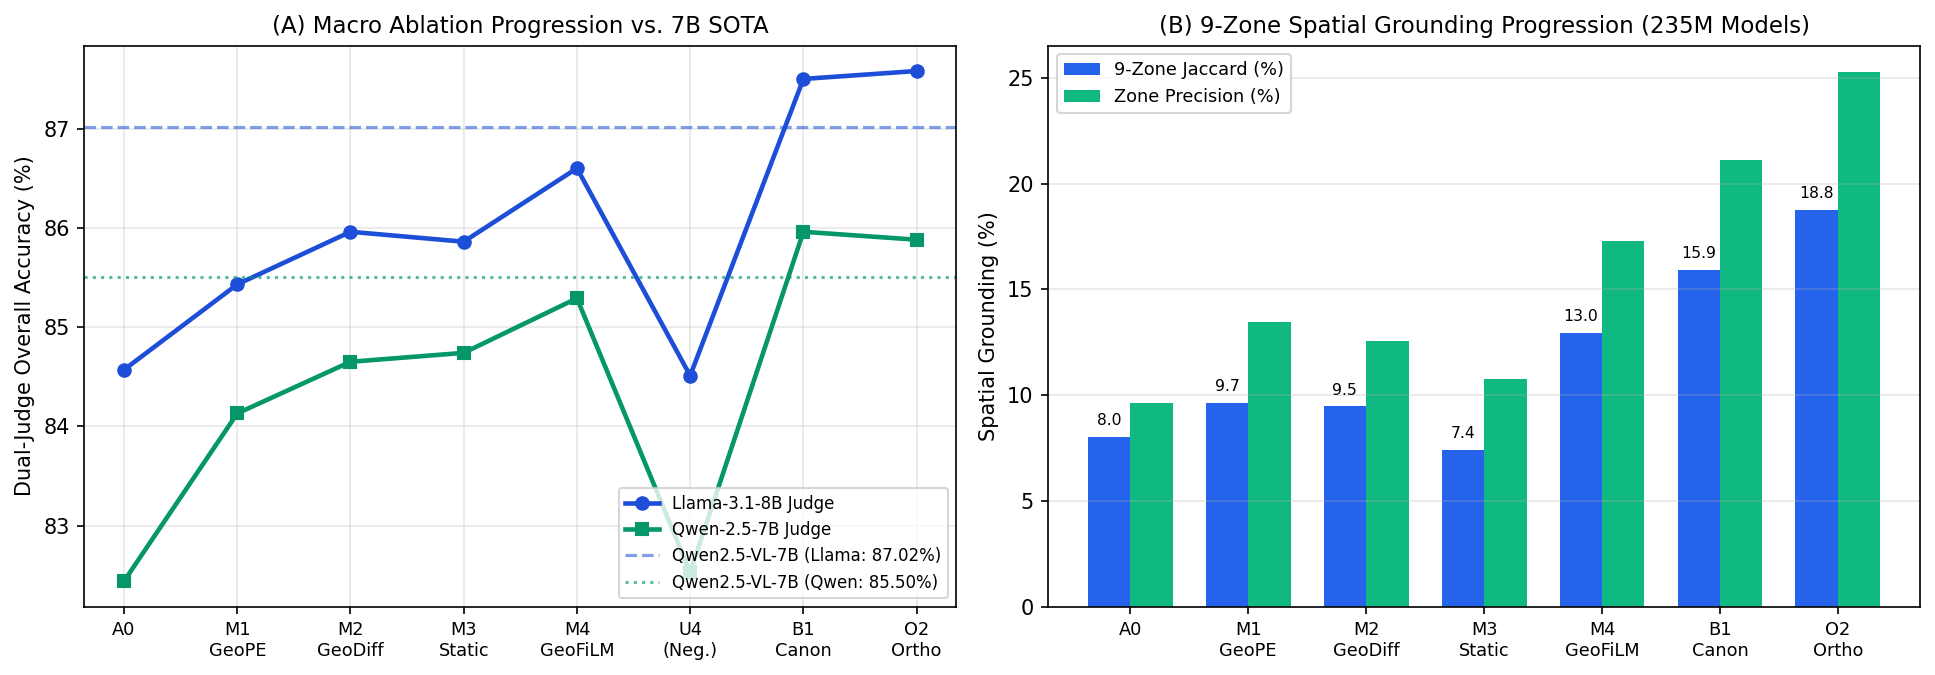

In [3]:
# [C2] Modul 1: Konsolidasi Tangga Ablasi Makro
dj_llama_o  = pd.read_csv(DATA_DIR / "ortho_unified_eval" / "summary_by_level_llama31_8b.csv")
dj_qwen_o   = pd.read_csv(DATA_DIR / "ortho_unified_eval" / "summary_by_level_qwen25_7b.csv")
dj_llama_p2 = pd.read_csv(DATA_DIR / "dual_judge_eval" / "summary_by_level_llama31_8b.csv")
dj_qwen_p2  = pd.read_csv(DATA_DIR / "dual_judge_eval" / "summary_by_level_qwen25_7b.csv")
txt_df      = pd.read_csv(DATA_DIR / "dual_judge_eval" / "text_metrics_paper2_all_models.csv")
spat_df     = pd.read_csv(DATA_DIR / "ortho_unified_eval" / "spatial_9grid_metrics.csv")
mcn_df      = pd.read_csv(DATA_DIR / "ortho_unified_eval" / "mcnemar_dual_judge_Ortho_O2_Ortho_Unified_Full.csv")
nrg_df      = pd.read_csv(DATA_DIR / "energy_efficiency_audit" / "exact_energy_computational_metrics.csv")

# Gabungkan baris GeoFiLMpp_U4_full dari dual_judge_eval agar ablasi negatif ikut tampil lengkap
llama_all = pd.concat([dj_llama_o, dj_llama_p2[dj_llama_p2["Model"] == "GeoFiLMpp_U4_full"]], ignore_index=True)
qwen_all  = pd.concat([dj_qwen_o,  dj_qwen_p2[dj_qwen_p2["Model"] == "GeoFiLMpp_U4_full"]], ignore_index=True)

MODEL_ORDER = [
    ("A0_VQAonly_r32",              "A0: Florence-2 Vanilla (LoRA r=32)"),
    ("M1_GeoPE_r32",                "M1: + 2D Continuous Fourier (GeoPE)"),
    ("M2_GeoDiff_r32",              "M2: + Lesion-Mucosa Diff (GeoDiff)"),
    ("M3_StaticGate_r32",           "M3: + Static Residual Gate"),
    ("M4_GeoFiLM_r32",              "M4: + Question-Conditioned FiLM (GeoFiLM)"),
    ("GeoFiLMpp_U4_full",           "U4: GeoFiLM++ Per-Patch Multi-Slot (Neg. Ablation)"),
    ("Bridge_B1_M4_CanonBridge",    "B1: M4 + Unconstrained Additive CanonBridge"),
    ("Ortho_O2_Ortho_Unified_Full", "O2: M4 + OrthoUnifiedBridge (Proposed)"),
    ("Gautam_Qwen2.5VL_7B",         "SOTA 7B: Qwen2.5-VL-7B-ft (Gautam et al.)"),
]

txt_map = {}
for _, r in txt_df.iterrows():
    k = "Bridge_B1_M4_CanonBridge" if r["Model"] == "B1_M4_CanonBridge" else r["Model"]
    txt_map[k] = (r["Token_F1 (%)"], r["ROUGE-L"], r["BLEU-4"])

spat_map  = {r["Model"]: (r["9-Zone Jaccard (%)"], r["Zone Precision (%)"]) for _, r in spat_df.iterrows()}
llama_map = {r["Model"]: r for _, r in llama_all.iterrows()}
qwen_map  = {r["Model"]: r for _, r in qwen_all.iterrows()}

base_l = float(llama_map["A0_VQAonly_r32"]["Overall (%)"])
base_q = float(qwen_map["A0_VQAonly_r32"]["Overall (%)"])

rows_m1 = []
for key, label in MODEL_ORDER:
    rl = llama_map.get(key)
    rq = qwen_map.get(key)
    l_ov = float(rl["Overall (%)"]) if rl is not None else np.nan
    q_ov = float(rq["Overall (%)"]) if rq is not None else np.nan
    l1_d = float(rl["L1_Det (%)"])  if rl is not None else np.nan
    tf1, rl_s, b4 = txt_map.get(key, (np.nan, np.nan, np.nan))
    sj, sp = spat_map.get(key, (np.nan, np.nan))
    rows_m1.append({
        "Model_Key": key,
        "Stage_Description": label,
        "L1_Det (%)": l1_d,
        "Llama_Overall (%)": l_ov,
        "dLlama_vs_A0 (pp)": round(l_ov - base_l, 2) if not np.isnan(l_ov) else np.nan,
        "Qwen_Overall (%)": q_ov,
        "dQwen_vs_A0 (pp)": round(q_ov - base_q, 2) if not np.isnan(q_ov) else np.nan,
        "Token_F1 (%)": tf1,
        "9Grid_Jaccard (%)": sj,
        "9Grid_Prec (%)": sp,
    })

df_m1 = pd.DataFrame(rows_m1)
df_m1.to_csv(OUT_DIR / "cara2_m1_macro_ablation_ladder.csv", index=False)
print("=== TANGGA ABLASI MAKRO TERPADU ===")
display(df_m1)

# Plot tangga ablasi makro
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
plot_df = df_m1[df_m1["Model_Key"] != "Gautam_Qwen2.5VL_7B"].copy().reset_index(drop=True)
short_lbl = ["A0", "M1\nGeoPE", "M2\nGeoDiff", "M3\nStatic", "M4\nGeoFiLM", "U4\n(Neg.)", "B1\nCanon", "O2\nOrtho"]

x = np.arange(len(plot_df))
axes[0].plot(x, plot_df["Llama_Overall (%)"], marker="o", lw=2.2, label="Llama-3.1-8B Judge", color="#1d4ed8")
axes[0].plot(x, plot_df["Qwen_Overall (%)"],  marker="s", lw=2.2, label="Qwen-2.5-7B Judge",  color="#059669")
axes[0].axhline(float(llama_map["Gautam_Qwen2.5VL_7B"]["Overall (%)"]), ls="--", color="#1d4ed8", alpha=0.55, label="Qwen2.5-VL-7B (Llama: 87.02%)")
axes[0].axhline(float(qwen_map["Gautam_Qwen2.5VL_7B"]["Overall (%)"]),  ls=":",  color="#059669", alpha=0.65, label="Qwen2.5-VL-7B (Qwen: 85.50%)")
axes[0].set_xticks(x); axes[0].set_xticklabels(short_lbl, fontsize=8.5)
axes[0].set_ylabel("Dual-Judge Overall Accuracy (%)")
axes[0].set_title("(A) Macro Ablation Progression vs. 7B SOTA")
axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8, loc="lower right")

spat_plot = plot_df.dropna(subset=["9Grid_Jaccard (%)"])
xs = np.arange(len(spat_plot))
lbl_s = [short_lbl[i] for i in spat_plot.index]
bars  = axes[1].bar(xs - 0.18, spat_plot["9Grid_Jaccard (%)"], width=0.36, label="9-Zone Jaccard (%)", color="#2563eb")
bars2 = axes[1].bar(xs + 0.18, spat_plot["9Grid_Prec (%)"],    width=0.36, label="Zone Precision (%)", color="#10b981")
for b in bars:
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.4, f"{b.get_height():.1f}", ha="center", va="bottom", fontsize=7.5)
axes[1].set_xticks(xs); axes[1].set_xticklabels(lbl_s, fontsize=8.5)
axes[1].set_ylabel("Spatial Grounding (%)")
axes[1].set_title("(B) 9-Zone Spatial Grounding Progression (235M Models)")
axes[1].grid(axis="y", alpha=0.3); axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.savefig(OUT_DIR / "fig1_macro_ablation_ladder.png", bbox_inches="tight")
plt.show()


## Modul 2 — Bukti Mekanistik Gram-Schmidt: Verifikasi Ortogonalitas Eksak FP32 (`N = 15,955`)

Mengaudit berkas `ortho_diag.json` pada seluruh 15.955 sampel uji untuk memverifikasi secara numerik bahwa injeksi global (`cos_glob`) dan injeksi spasial per-patch (`cos_spat`) ortogonal secara eksak terhadap ruang fitur visual dasar di seluruh tingkat kompleksitas (L1, L2, L3).


=== VERIFIKASI ORTOGONALITAS EKSAK GRAM-SCHMIDT (FP32) ===


,Vector_Pair,Subset,N,Mean,Std,Median,P95,P99,Max,Pct_Below_1e-6 (%)
0,"|cos(glob_perp, e_total)|","ALL (N=15,955)",15955,1.504271e-08,3.255035e-09,1.488188e-08,2.093359e-08,2.355238e-08,2.737652e-08,100.0
1,"|cos(inj_perp, pe_2d)|","ALL (N=15,955)",15955,4.870733e-08,5.735472e-10,4.870428e-08,4.964208e-08,4.996214e-08,5.051571e-08,100.0
2,"|cos(glob_perp, e_total)|",Complexity=1,5496,1.513537e-08,3.286892e-09,1.494701e-08,2.102720e-08,2.381328e-08,2.737652e-08,100.0
3,"|cos(inj_perp, pe_2d)|",Complexity=1,5496,4.864243e-08,5.693657e-10,4.864129e-08,4.958455e-08,4.990511e-08,5.051571e-08,100.0
4,"|cos(glob_perp, e_total)|",Complexity=2,5251,1.505304e-08,3.241015e-09,1.490367e-08,2.092674e-08,2.353739e-08,2.737652e-08,100.0
5,"|cos(inj_perp, pe_2d)|",Complexity=2,5251,4.874515e-08,5.699787e-10,4.873344e-08,4.967467e-08,5.004512e-08,5.051571e-08,100.0
6,"|cos(glob_perp, e_total)|",Complexity=3,5208,1.493453e-08,3.232071e-09,1.476879e-08,2.078177e-08,2.349772e-08,2.737652e-08,100.0
7,"|cos(inj_perp, pe_2d)|",Complexity=3,5208,4.873770e-08,5.755911e-10,4.874185e-08,4.965910e-08,4.997672e-08,5.051571e-08,100.0


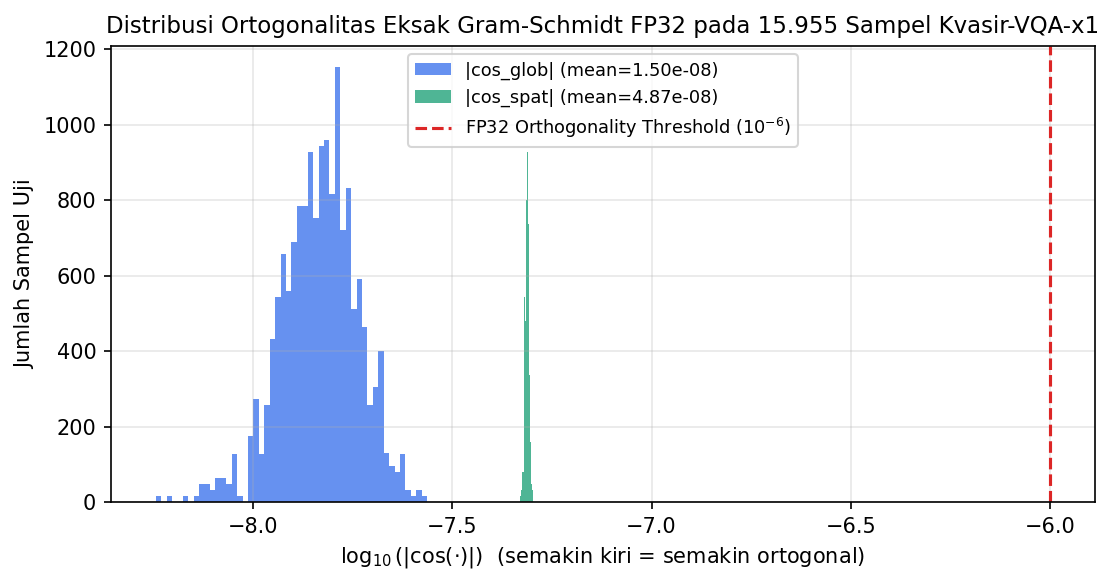

In [4]:
# [C3] Modul 2: Audit Numerik Ortogonalitas Gram-Schmidt (FP32)
O2_RUN_DIR = EXP_DIR / "Paper3_Ortho_Unified_r32" / "20261116-000618_O2_Ortho_Unified_Full_r32_s42"
B1_RUN_DIR = EXP_DIR / "Paper2plus_Bridge_r32" / "20261103-050623_B1_M4_CanonBridge_r32_s42"

ortho_diag_raw = json.loads((O2_RUN_DIR / "eval" / "ortho_diag.json").read_text(encoding="utf-8"))
ortho_diag = {int(k): v for k, v in ortho_diag_raw.items()}
assert len(ortho_diag) == len(te), f"Mismatch ortho_diag ({len(ortho_diag)}) vs test ({len(te)})"

cos_g = np.array([abs(float(ortho_diag[i]["cos_glob"])) for i in range(len(te))])
cos_s = np.array([abs(float(ortho_diag[i]["cos_spat"])) for i in range(len(te))])
comp_col = te["complexity"].astype(str).values if "complexity" in te.columns else np.array(["ALL"] * len(te))

def summarize_vec(name, subset_lbl, arr):
    return {
        "Vector_Pair": name,
        "Subset": subset_lbl,
        "N": len(arr),
        "Mean": float(np.mean(arr)),
        "Std": float(np.std(arr)),
        "Median": float(np.median(arr)),
        "P95": float(np.percentile(arr, 95)),
        "P99": float(np.percentile(arr, 99)),
        "Max": float(np.max(arr)),
        "Pct_Below_1e-6 (%)": round(100.0 * float(np.mean(arr < 1e-6)), 4),
    }

gs_rows = [
    summarize_vec("|cos(glob_perp, e_total)|", "ALL (N=15,955)", cos_g),
    summarize_vec("|cos(inj_perp, pe_2d)|",    "ALL (N=15,955)", cos_s),
]
for lv in sorted(set(comp_col)):
    mask = (comp_col == lv)
    gs_rows.append(summarize_vec("|cos(glob_perp, e_total)|", f"Complexity={lv}", cos_g[mask]))
    gs_rows.append(summarize_vec("|cos(inj_perp, pe_2d)|",    f"Complexity={lv}", cos_s[mask]))

df_gs = pd.DataFrame(gs_rows)
df_gs.to_csv(OUT_DIR / "cara2_m2_gram_schmidt_stats.csv", index=False)
print("=== VERIFIKASI ORTOGONALITAS EKSAK GRAM-SCHMIDT (FP32) ===")
display(df_gs)

# Plot distribusi log10(|cos|)
fig, ax = plt.subplots(figsize=(7.5, 4.0))
ax.hist(np.log10(np.clip(cos_g, 1e-12, None)), bins=50, alpha=0.70, label=f"|cos_glob| (mean={cos_g.mean():.2e})", color="#2563eb")
ax.hist(np.log10(np.clip(cos_s, 1e-12, None)), bins=50, alpha=0.70, label=f"|cos_spat| (mean={cos_s.mean():.2e})", color="#059669")
ax.axvline(np.log10(1e-6), color="#dc2626", ls="--", lw=1.5, label="FP32 Orthogonality Threshold ($10^{-6}$)")
ax.set_xlabel(r"$\log_{10}(|\cos(\cdot)|)$  (semakin kiri = semakin ortogonal)")
ax.set_ylabel("Jumlah Sampel Uji")
ax.set_title("Distribusi Ortogonalitas Eksak Gram-Schmidt FP32 pada 15.955 Sampel Kvasir-VQA-x1")
ax.legend(fontsize=8.5); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig2_gram_schmidt_orthogonality.png", bbox_inches="tight")
plt.show()


## Modul 3 — Bukti Mekanistik Supervised Query-Aspect Router (`ortho_diag.json` vs Ground-Truth `question_class`)

Mengevaluasi kinerja **Query-Aspect Router** (`router_cats` dengan threshold $\sigma \ge 0.5$) terhadap label aspek ground-truth pada seluruh 15.955 query uji (dibatasi pada 16 kategori kanonik di `canon_specs.json`):
- **Micro & Macro Precision / Recall / F1**
- **Non-Target Category Suppression Rate (Specificity):** Persentase kategori non-target (hingga 15 dari 16 kategori pada query L1 tunggal) yang berhasil ditekan oleh router agar tidak mencemari fusi fitur (`0.25x` background vs `2.0x` target).
- Breakdown per tingkat kompleksitas (L1 vs L2 vs L3) dan per kategori kanonik.


=== RINGKASAN AUDIT SUPERVISED QUERY-ASPECT ROUTER ===


,Subset,N_Queries,Avg_GT_Cats,Avg_Pred_Cats,Micro_Prec (%),Micro_Rec (%),Micro_F1 (%),Macro_F1 (%),NonTarget_Suppression (%),Exact_Set_Match (%)
0,"ALL (N=15,955)",15955,1.96,0.92,21.81,10.18,13.88,11.19,94.90,2.19
1,Complexity=1,5496,0.95,0.79,9.84,8.10,8.89,3.86,95.29,5.93
2,Complexity=2,5251,2.00,0.90,24.67,11.12,15.33,11.14,95.16,0.44
3,Complexity=3,5208,2.99,1.07,28.66,10.24,15.09,10.89,94.14,0.00
4,Single-Aspect (|GT|=1),5273,1.00,0.78,10.42,8.17,9.16,4.00,95.32,5.58
5,Multi-Aspect (|GT|>=2),10433,2.50,0.98,26.85,10.58,15.18,11.55,94.67,0.20



=== DETAIL ROUTER PER 16 KATEGORI KANONIK ===


,Category,GT_Count,Pred_Count,Precision (%),Recall (%),F1 (%),NonTarget_Suppression (%)
13,polyp_type,1944,1850,42.76,40.69,41.70,92.44
12,polyp_size,1925,710,65.35,24.10,35.22,98.25
11,polyp_removal_status,2312,1664,27.82,20.03,23.29,91.20
4,finding_count,2115,2555,17.42,21.04,19.06,84.75
10,polyp_count,1900,1368,21.13,15.21,17.69,92.32
6,instrument_location,1913,3507,8.35,15.32,10.81,77.11
14,procedure_type,2303,1542,12.65,8.47,10.14,90.13
2,abnormality_presence,1823,564,18.62,5.76,8.80,96.75
5,instrument_count,2208,416,25.48,4.80,8.08,97.74
9,landmark_presence,1264,381,9.19,2.77,4.26,97.64


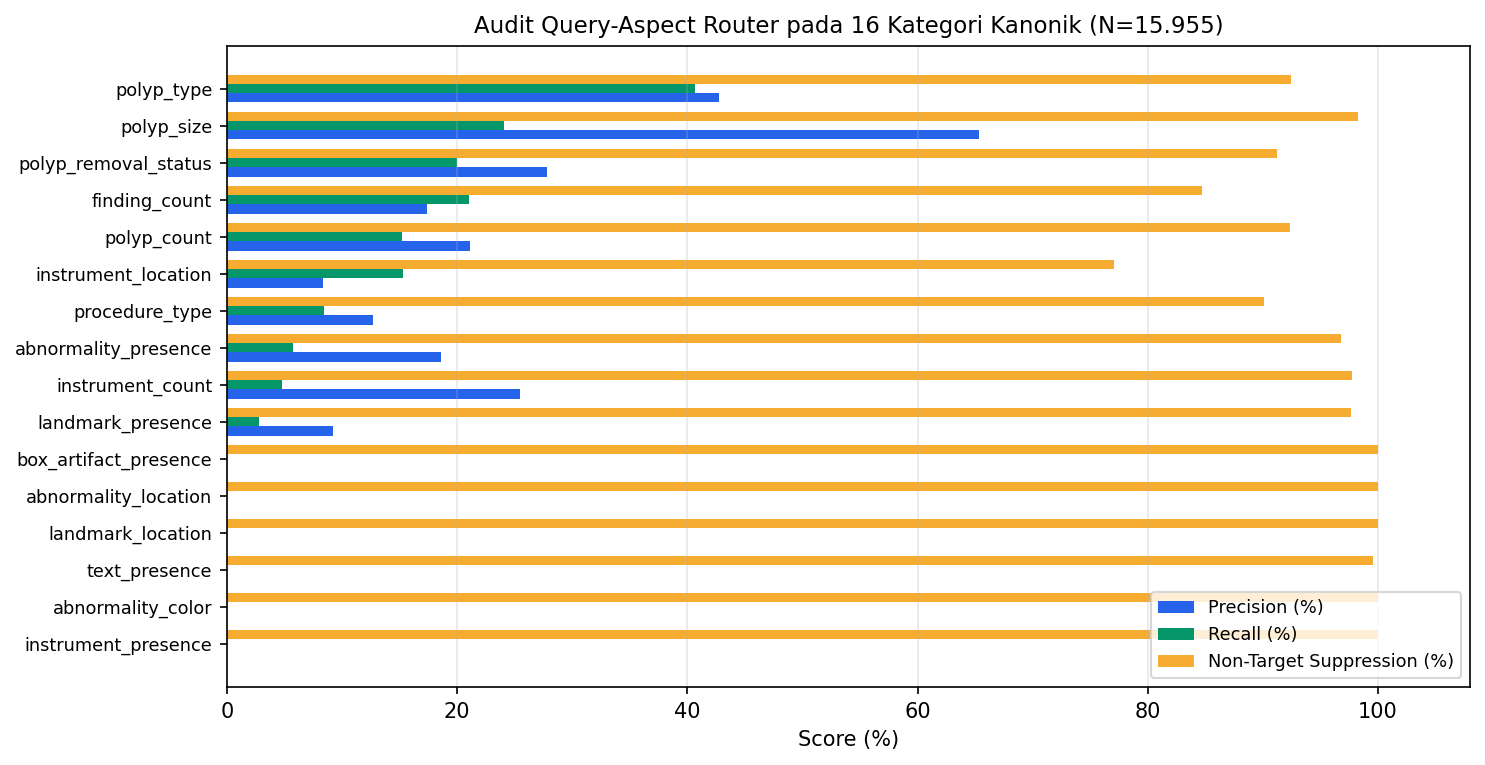

In [5]:
# [C4] Modul 3: Audit Kuantitatif Supervised Query-Aspect Router
canon_specs = json.loads((O2_RUN_DIR / "canon_specs.json").read_text(encoding="utf-8"))
CANON_CATS = sorted(canon_specs.keys())
C = len(CANON_CATS)
cat2idx = {c: i for i, c in enumerate(CANON_CATS)}

Y_true = np.zeros((len(te), C), dtype=int)
Y_pred = np.zeros((len(te), C), dtype=int)

for i in range(len(te)):
    gt_cats = [c for c in as_class_list(te.iloc[i]["question_class"]) if c in cat2idx]
    pr_cats = [c for c in ortho_diag[i].get("router_cats", []) if c in cat2idx]
    for c in gt_cats:
        Y_true[i, cat2idx[c]] = 1
    for c in pr_cats:
        Y_pred[i, cat2idx[c]] = 1

def compute_router_metrics(yt, yp, subset_name):
    tp = int(((yt == 1) & (yp == 1)).sum())
    fp = int(((yt == 0) & (yp == 1)).sum())
    fn = int(((yt == 1) & (yp == 0)).sum())
    tn = int(((yt == 0) & (yp == 0)).sum())
    prec_micro = tp / max(tp + fp, 1)
    rec_micro  = tp / max(tp + fn, 1)
    f1_micro   = 2 * prec_micro * rec_micro / max(prec_micro + rec_micro, 1e-12)
    supp_rate  = tn / max(tn + fp, 1)  # True Negative Rate = Non-Target Suppression Rate
    exact_set  = float(np.mean(np.all(yt == yp, axis=1)))
    p_c, r_c, f1_c, _ = precision_recall_fscore_support(yt, yp, average=None, zero_division=0)
    return {
        "Subset": subset_name,
        "N_Queries": len(yt),
        "Avg_GT_Cats": round(float(yt.sum(axis=1).mean()), 2),
        "Avg_Pred_Cats": round(float(yp.sum(axis=1).mean()), 2),
        "Micro_Prec (%)": round(100 * prec_micro, 2),
        "Micro_Rec (%)": round(100 * rec_micro, 2),
        "Micro_F1 (%)": round(100 * f1_micro, 2),
        "Macro_F1 (%)": round(100 * float(np.mean(f1_c)), 2),
        "NonTarget_Suppression (%)": round(100 * supp_rate, 2),
        "Exact_Set_Match (%)": round(100 * exact_set, 2),
    }

r_summary = [compute_router_metrics(Y_true, Y_pred, "ALL (N=15,955)")]
for lv in sorted(set(comp_col)):
    m = (comp_col == lv)
    r_summary.append(compute_router_metrics(Y_true[m], Y_pred[m], f"Complexity={lv}"))

n_gt_cats = Y_true.sum(axis=1)
r_summary.append(compute_router_metrics(Y_true[n_gt_cats == 1], Y_pred[n_gt_cats == 1], "Single-Aspect (|GT|=1)"))
r_summary.append(compute_router_metrics(Y_true[n_gt_cats >= 2], Y_pred[n_gt_cats >= 2], "Multi-Aspect (|GT|>=2)"))

df_router_sum = pd.DataFrame(r_summary)
df_router_sum.to_csv(OUT_DIR / "cara2_m3_router_summary.csv", index=False)
print("=== RINGKASAN AUDIT SUPERVISED QUERY-ASPECT ROUTER ===")
display(df_router_sum)

# Per-category router metrics
p_c, r_c, f1_c, sup_c = precision_recall_fscore_support(Y_true, Y_pred, average=None, zero_division=0)
per_cat_rows = []
for ci, c in enumerate(CANON_CATS):
    tn_c = int(((Y_true[:, ci] == 0) & (Y_pred[:, ci] == 0)).sum())
    fp_c = int(((Y_true[:, ci] == 0) & (Y_pred[:, ci] == 1)).sum())
    per_cat_rows.append({
        "Category": c,
        "GT_Count": int(sup_c[ci]),
        "Pred_Count": int(Y_pred[:, ci].sum()),
        "Precision (%)": round(100 * float(p_c[ci]), 2),
        "Recall (%)": round(100 * float(r_c[ci]), 2),
        "F1 (%)": round(100 * float(f1_c[ci]), 2),
        "NonTarget_Suppression (%)": round(100 * tn_c / max(tn_c + fp_c, 1), 2),
    })
df_router_cat = pd.DataFrame(per_cat_rows).sort_values("F1 (%)", ascending=False)
df_router_cat.to_csv(OUT_DIR / "cara2_m3_router_per_category.csv", index=False)
print("\n=== DETAIL ROUTER PER 16 KATEGORI KANONIK ===")
display(df_router_cat)

# Plot Router Precision/Recall/Suppression
fig, ax = plt.subplots(figsize=(10, 5.2))
dplot = df_router_cat.sort_values("F1 (%)", ascending=True)
y = np.arange(len(dplot))
ax.barh(y - 0.25, dplot["Precision (%)"], height=0.25, label="Precision (%)", color="#2563eb")
ax.barh(y,        dplot["Recall (%)"],    height=0.25, label="Recall (%)",    color="#059669")
ax.barh(y + 0.25, dplot["NonTarget_Suppression (%)"], height=0.25, label="Non-Target Suppression (%)", color="#f59e0b", alpha=0.85)
ax.set_yticks(y); ax.set_yticklabels(dplot["Category"], fontsize=8.5)
ax.set_xlabel("Score (%)"); ax.set_xlim(0, 108)
ax.set_title("Audit Query-Aspect Router pada 16 Kategori Kanonik (N=15.955)")
ax.legend(loc="lower right", fontsize=8.5); ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig3_router_diagnostics.png", bbox_inches="tight")
plt.show()


## Modul 4 — Bukti Mekanistik 9D Moments + 2D Fourier Centroid (`O2` vs `B1` & 9-Grid Per Kategori)

1. **Selective Geometric Gain pada Encoder Head (`O2` vs `B1`):** Membandingkan perubahan akurasi 16 encoder head antara grup *Spatial/Geometric* vs *Non-Spatial/Appearance*.
2. **Breakdown 9-Grid Spatial Grounding per Kategori (`abnormality_location`, `instrument_location`, `landmark_location`):** Menghitung ulang langsung dari `predictions.json` seluruh model (`M1–M4`, `U4`, `B1`, `O2_Raw`, `O2_Aligned`) untuk membuktikan kontribusi komponen spasial & alignment.


=== SELECTIVE GEOMETRIC GAIN: ENCODER HEAD (O2 vs B1) ===


,Group,N_Categories,Mean_B1,Mean_O2,Mean_Delta_pp,Max_Delta_pp
0,Non-Spatial / Semantic,12,90.72,90.43,-0.29,4.84
1,Spatial/Geometric (9D+Fourier/CORN),4,65.00,69.73,4.74,10.72


,kategori,n_test,B1_CanonBridge_Head_%,Ortho_Unified_Head_%,Δ_Head_pp,multi,Group
4,instrument_location,1913,69.26,79.98,10.72,True,Spatial/Geometric (9D+Fourier/CORN)
5,polyp_size,1925,72.73,80.26,7.53,True,Spatial/Geometric (9D+Fourier/CORN)
8,instrument_presence,1837,90.75,95.59,4.84,True,Non-Spatial / Semantic
2,abnormality_location,1897,62.84,63.78,0.94,True,Spatial/Geometric (9D+Fourier/CORN)
9,box_artifact_presence,2319,97.02,97.24,0.22,False,Non-Spatial / Semantic
12,instrument_count,2208,98.23,98.41,0.18,False,Non-Spatial / Semantic
7,landmark_presence,1260,92.70,92.78,0.08,False,Non-Spatial / Semantic
13,abnormality_presence,1823,98.35,98.41,0.06,True,Non-Spatial / Semantic
15,procedure_type,2303,99.83,99.83,0.00,False,Non-Spatial / Semantic
14,polyp_removal_status,2312,98.92,98.83,-0.09,False,Non-Spatial / Semantic


✓ Model predictions dimuat: ['M1_GeoPE_r32', 'M2_GeoDiff_r32', 'M3_StaticGate_r32', 'M4_GeoFiLM_r32', 'GeoFiLMpp_U4_full', 'B1_M4_CanonBridge', 'O2_Raw_Decoder', 'O2_Ortho_Unified_Full']

=== 9-GRID SPATIAL GROUNDING PER KATEGORI (TERMASUK O2_Raw vs O2_Aligned) ===


,Scope,Model,N_With_GT_Zone,Jaccard (%),Recall (%),Precision (%),Hedge_ge3 (%),Avg_Zones
3,ALL_LOCATION_COMBINED,M1_GeoPE_r32,983,9.65,11.57,13.45,3.97,0.38
7,ALL_LOCATION_COMBINED,M2_GeoDiff_r32,983,9.47,11.53,12.58,4.88,0.39
11,ALL_LOCATION_COMBINED,M3_StaticGate_r32,983,7.42,8.86,10.76,1.63,0.24
15,ALL_LOCATION_COMBINED,M4_GeoFiLM_r32,983,12.96,16.34,17.29,5.90,0.54
19,ALL_LOCATION_COMBINED,GeoFiLMpp_U4_full,983,10.25,12.96,16.68,6.71,0.44
23,ALL_LOCATION_COMBINED,B1_M4_CanonBridge,983,15.93,19.51,21.11,7.63,0.64
27,ALL_LOCATION_COMBINED,O2_Raw_Decoder,983,18.76,21.84,25.27,6.61,0.65
31,ALL_LOCATION_COMBINED,O2_Ortho_Unified_Full,983,22.99,28.59,29.79,6.82,0.79


Scope,ALL_LOCATION_COMBINED,abnormality_location,instrument_location,landmark_location
Model,,,,
M1_GeoPE_r32,9.65,6.51,16.22,2.80
M2_GeoDiff_r32,9.47,8.44,13.36,5.05
M3_StaticGate_r32,7.42,2.68,15.24,0.81
M4_GeoFiLM_r32,12.96,10.73,19.63,2.65
GeoFiLMpp_U4_full,10.25,6.67,16.95,1.83
B1_M4_CanonBridge,15.93,14.19,22.14,4.81
O2_Raw_Decoder,18.76,16.81,25.27,5.34
O2_Ortho_Unified_Full,22.99,20.06,31.27,5.34


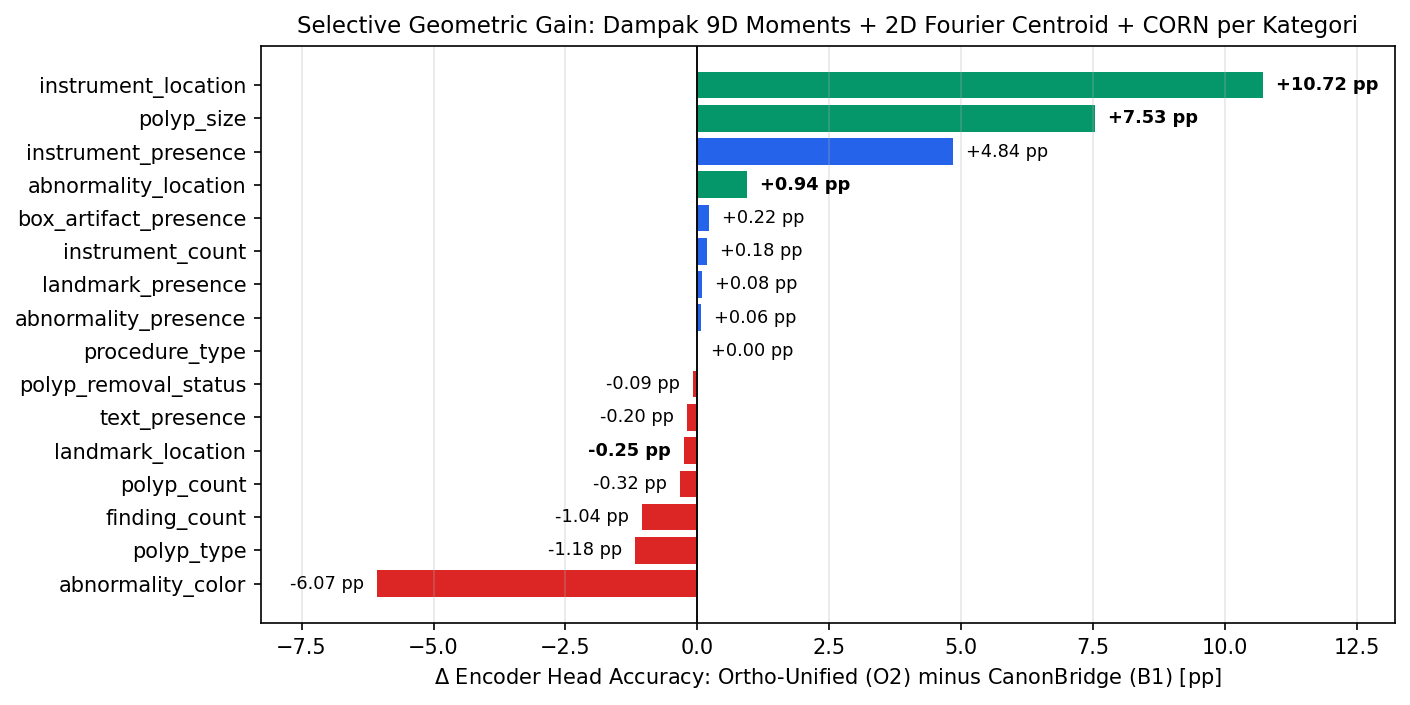

In [6]:
# [C5] Modul 4: Selective Geometric Gain & Breakdown 9-Grid Per Kategori
head_df = pd.read_csv(DATA_DIR / "ortho_unified_eval" / "encoder_head_accuracy_ortho_vs_b1.csv")

GEOM_CATS = {"instrument_location", "abnormality_location", "landmark_location", "polyp_size"}
head_df["Group"] = head_df["kategori"].apply(lambda c: "Spatial/Geometric (9D+Fourier/CORN)" if c in GEOM_CATS else "Non-Spatial / Semantic")
grp_summary = head_df.groupby("Group").agg(
    N_Categories=("kategori", "count"),
    Mean_B1=("B1_CanonBridge_Head_%", "mean"),
    Mean_O2=("Ortho_Unified_Head_%", "mean"),
    Mean_Delta_pp=("Δ_Head_pp", "mean"),
    Max_Delta_pp=("Δ_Head_pp", "max"),
).reset_index()
grp_summary.to_csv(OUT_DIR / "cara2_m4_selective_geometric_gain.csv", index=False)
print("=== SELECTIVE GEOMETRIC GAIN: ENCODER HEAD (O2 vs B1) ===")
display(grp_summary.round(2))
display(head_df.sort_values("Δ_Head_pp", ascending=False))

# Muat predictions.json seluruh model yang tersedia di data/experiments/
PRED_PATHS = {
    "M1_GeoPE_r32":          EXP_DIR / "Paper2_GeoFiLM_r32/20261030-212438_M1_GeoPE_r32_s42/eval/predictions.json",
    "M2_GeoDiff_r32":        EXP_DIR / "Paper2_GeoFiLM_r32/20261031-142834_M2_GeoDiff_r32_s42/eval/predictions.json",
    "M3_StaticGate_r32":     EXP_DIR / "Paper2_GeoFiLM_r32/20261031-235417_M3_StaticGate_r32_s42/eval/predictions.json",
    "M4_GeoFiLM_r32":        EXP_DIR / "Paper2_GeoFiLM_r32/20261029-134314_M4_GeoFiLM_r32_s42/eval/predictions.json",
    "GeoFiLMpp_U4_full":     EXP_DIR / "Paper2plus_GeoFiLMpp_r32/20261102-073101_U4_full_r32_s42/eval/predictions.json",
    "B1_M4_CanonBridge":     B1_RUN_DIR / "eval/predictions.json",
    "O2_Raw_Decoder":        O2_RUN_DIR / "eval/predictions_raw.json",
    "O2_Ortho_Unified_Full": O2_RUN_DIR / "eval/predictions.json",
}

def load_preds_dict(p: Path):
    raw = json.loads(p.read_text(encoding="utf-8"))
    if isinstance(raw, dict):
        out = {}
        for k, v in raw.items():
            idx = int(k)
            out[idx] = v["pred"] if isinstance(v, dict) and "pred" in v else str(v)
        return out
    elif isinstance(raw, list):
        return {i: (x["pred"] if isinstance(x, dict) and "pred" in x else str(x)) for i, x in enumerate(raw)}
    return {}

ALL_PREDS = {name: load_preds_dict(p) for name, p in PRED_PATHS.items() if p.exists()}
print("✓ Model predictions dimuat:", list(ALL_PREDS.keys()))

ZONES_9 = [
    "upper-left", "upper-center", "upper-right",
    "center-left", "center", "center-right",
    "lower-left", "lower-center", "lower-right",
]
ZONE_PATS = {
    z: re.compile(r"\b" + z.replace("-", r"[\s\-]+") + r"\b", re.I)
    for z in sorted(ZONES_9, key=len, reverse=True)
}
def extract_zones(text: str) -> set:
    s = str(text).lower()
    out = set()
    for z in sorted(ZONES_9, key=len, reverse=True):
        if ZONE_PATS[z].search(s):
            out.add(z)
            s = ZONE_PATS[z].sub(" ", s)
    return out

LOC_CATS = ["abnormality_location", "instrument_location", "landmark_location"]
row_cats_list = [set(as_class_list(te.iloc[i]["question_class"])) for i in range(len(te))]
gt_zones_list = [extract_zones(te.iloc[i]["answer"]) for i in range(len(te))]

spat_cat_rows = []
for m_name, preds_d in ALL_PREDS.items():
    for cat_scope in LOC_CATS + ["ALL_LOCATION_COMBINED"]:
        jacc_l, rec_l, prec_l, hedge_l, nz_l = [], [], [], [], []
        for i in range(len(te)):
            rc = row_cats_list[i]
            match = (any(c in rc for c in LOC_CATS) if cat_scope == "ALL_LOCATION_COMBINED" else (cat_scope in rc))
            if not match:
                continue
            gz = gt_zones_list[i]
            if not gz:
                continue
            pz = extract_zones(preds_d.get(i, ""))
            jacc_l.append(len(gz & pz) / max(len(gz | pz), 1))
            rec_l.append(len(gz & pz) / len(gz))
            prec_l.append(len(gz & pz) / len(pz) if pz else 0.0)
            hedge_l.append(1.0 if len(pz) >= 3 else 0.0)
            nz_l.append(len(pz))
        spat_cat_rows.append({
            "Scope": cat_scope,
            "Model": m_name,
            "N_With_GT_Zone": len(jacc_l),
            "Jaccard (%)": round(100 * float(np.mean(jacc_l)), 2) if jacc_l else 0.0,
            "Recall (%)": round(100 * float(np.mean(rec_l)), 2) if rec_l else 0.0,
            "Precision (%)": round(100 * float(np.mean(prec_l)), 2) if prec_l else 0.0,
            "Hedge_ge3 (%)": round(100 * float(np.mean(hedge_l)), 2) if hedge_l else 0.0,
            "Avg_Zones": round(float(np.mean(nz_l)), 2) if nz_l else 0.0,
        })

df_spat_cat = pd.DataFrame(spat_cat_rows)
df_spat_cat.to_csv(OUT_DIR / "cara2_m4_spatial_9grid_per_category.csv", index=False)
print("\n=== 9-GRID SPATIAL GROUNDING PER KATEGORI (TERMASUK O2_Raw vs O2_Aligned) ===")
display(df_spat_cat[df_spat_cat["Scope"] == "ALL_LOCATION_COMBINED"])
display(df_spat_cat.pivot(index="Model", columns="Scope", values="Jaccard (%)").reindex(list(ALL_PREDS.keys())))

# Plot Selective Geometric Gain (Δ Head Accuracy O2 vs B1)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
hd = head_df.sort_values("Δ_Head_pp", ascending=True)
colors = ["#059669" if (c in GEOM_CATS and v >= 0) else ("#2563eb" if v >= 0 else "#dc2626") for c, v in zip(hd["kategori"], hd["Δ_Head_pp"])]
ax.barh(hd["kategori"], hd["Δ_Head_pp"], color=colors)
ax.axvline(0, color="black", lw=0.9)
for idx, (cat, val) in enumerate(zip(hd["kategori"], hd["Δ_Head_pp"])):
    offset = 0.25 if val >= 0 else -0.25
    ha = "left" if val >= 0 else "right"
    ax.text(val + offset, idx, f"{val:+.2f} pp", va="center", ha=ha, fontsize=8.5, fontweight="bold" if cat in GEOM_CATS else "normal")
ax.set_xlabel(r"$\Delta$ Encoder Head Accuracy: Ortho-Unified (O2) minus CanonBridge (B1) [pp]")
ax.set_title("Selective Geometric Gain: Dampak 9D Moments + 2D Fourier Centroid + CORN per Kategori")
ax.set_xlim(hd["Δ_Head_pp"].min() - 2.2, hd["Δ_Head_pp"].max() + 2.5)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig4_selective_geometric_gain.png", bbox_inches="tight")
plt.show()


## Modul 5 — Perbaikan Bug Parser Ordinal `polyp_size` (`millimeters`/`mm`) & Audit CORN Head vs Decoder

Pada skrip evaluasi `07` sebelumnya, `SIZE_PATS` hanya mencocokkan satuan `mm` sehingga gagal menangkap frasa **`millimeters`** (yang dipakai mayoritas prediksi Florence-2, mis. *"polyp measuring 5 to 10 millimeters"*, *"greater than 20 millimeters"*), menyebabkan fallback konstan ke kelas `1` (`All_QWK = 0.0`).

Modul ini:
1. Memperbaiki regex satuan (`mm | millimeter(s) | millimetre(s)`) serta variasi frasa (`larger than 20`, `between 11 to 20`, dll.).
2. Menghitung **metrik ordinal yang benar** (`Parsed_Rate`, `Exact`, `Within-1`, `Norm-MAE`, `QWK`) untuk seluruh teks decoder (`M1–M4`, `U4`, `B1`, `O2_Raw`, `O2_Aligned`).
3. Mengevaluasi langsung **CORN Head (`corn_size_tier` di `ortho_diag.json`)** dan **Canon Head (`canon_preds.json` `B1` vs `O2`)**, sekaligus mengukur **Head-to-Decoder Readout Consistency** (`O2_Raw` vs `O2_Aligned`).


✓ Total aspek polyp_size (polip hadir) terdeteksi: N=733 (Single-Aspect L1: 106)
=== METRIK ORDINAL POLYP SIZE (FIXED REGEX: mm + millimeters) & CORN HEAD ===


,Source,N,Parsed_Rate (%),All_Exact (%),All_Within1 (%),All_Norm_MAE,All_QWK,Parsed_QWK,Single_N,Single_Exact (%)
0,Decoder: M1_GeoPE_r32,733,96.86,34.79,79.40,0.2956,0.1027,0.1087,106,28.30
1,Decoder: M2_GeoDiff_r32,733,97.27,33.42,80.49,0.2920,0.1197,0.1175,106,33.96
2,Decoder: M3_StaticGate_r32,733,96.59,35.61,79.81,0.2906,0.0859,0.0962,106,41.51
3,Decoder: M4_GeoFiLM_r32,733,97.54,41.88,89.09,0.2333,0.4280,0.4302,106,45.28
4,Decoder: GeoFiLMpp_U4_full,733,93.45,45.29,91.00,0.2160,0.5584,0.5764,106,50.94
5,Decoder: B1_M4_CanonBridge,733,97.54,66.58,97.00,0.1219,0.7656,0.7756,106,70.75
6,Decoder: O2_Raw_Decoder,733,97.95,74.08,98.36,0.0923,0.8192,0.8279,106,73.58
7,Decoder: O2_Ortho_Unified_Full,733,97.95,74.08,98.36,0.0923,0.8192,0.8279,106,73.58
8,EncoderHead: B1_Canon_Head,733,68.76,67.80,95.91,0.1214,0.7319,0.8800,106,66.98
9,EncoderHead: O2_Canon_Head,733,81.45,75.72,98.09,0.0873,0.8242,0.9076,106,77.36



[Head-to-Decoder Readout Consistency vs CORN Head (N=733)]
  O2_Raw_Decoder        : 86.90%
  O2_Ortho_Unified_Full : 86.90%  (Delta: +0.00 pp)


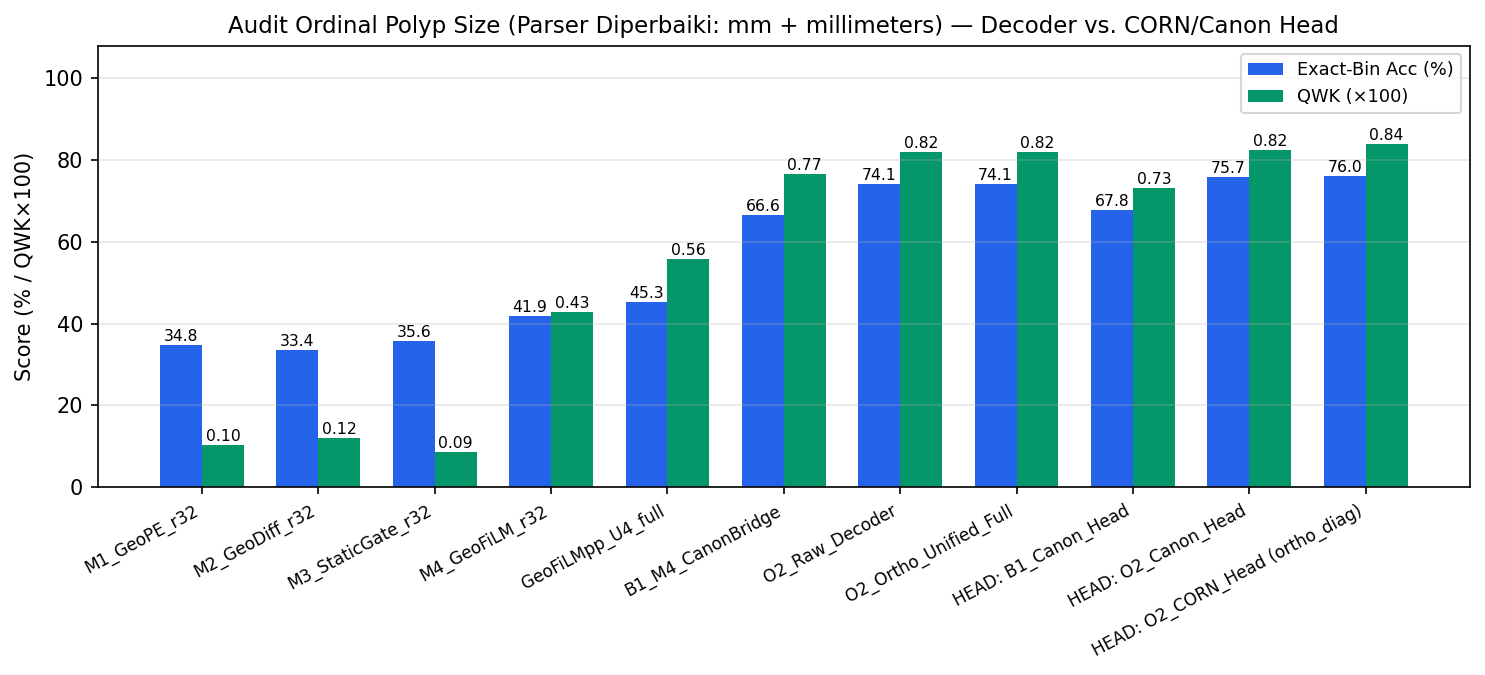

In [7]:
# [C6] Modul 5: Perbaikan Parser Ordinal polyp_size & Audit CORN Head vs Decoder
UNIT = r"(?:mm|millimeters?|millimetres?)"
SIZE_PATS_FIXED = [
    (0, re.compile(rf"(?:<\s*5\s*{UNIT}|(?:less|smaller|under|below)\s+than\s+5\s*{UNIT}|under\s+5\s*{UNIT}|diminutive)", re.I)),
    (1, re.compile(rf"(?:5\s*(?:[\-–]|to)\s*10\s*{UNIT}|between\s+5\s+(?:and|to)\s+10\s*{UNIT})", re.I)),
    (2, re.compile(rf"(?:1[01]\s*(?:[\-–]|to)\s*20\s*{UNIT}|between\s+1[01]\s+(?:and|to)\s+20\s*{UNIT})", re.I)),
    (3, re.compile(rf"(?:>\s*20\s*{UNIT}|(?:more|greater|larger|bigger|over|above)\s+than\s+20\s*{UNIT}|over\s+20\s*{UNIT})", re.I)),
]

def extract_size_ranks_fixed(text: str) -> list:
    s = str(text)
    return sorted({rk for rk, pat in SIZE_PATS_FIXED if pat.search(s)})

tier_map = {t: idx for idx, t in enumerate(POLYP_SIZE_ORDERED_TIERS)}  # {'<5mm':0, '5-10mm':1, '11-20mm':2, '>20mm':3}

gt_size_items = []
for i in range(len(te)):
    row = te.iloc[i]
    row_cats = as_class_list(row["question_class"])
    for c, a in (aspect_pairs(row["question_class"], row["original"]) or []):
        if c == "polyp_size":
            gt_rks = [tier_map[at] for at in atoms(a) if at in tier_map]
            if gt_rks:
                gt_size_items.append((i, gt_rks, max(gt_rks), len(gt_rks) == 1 and len(row_cats) == 1))

print(f"✓ Total aspek polyp_size (polip hadir) terdeteksi: N={len(gt_size_items)} (Single-Aspect L1: {sum(x[3] for x in gt_size_items)})")

def eval_ordinal_predictions(name, pred_rank_fn):
    gt_all, pr_all, parsed_flags = [], [], []
    gt_s1, pr_s1 = [], []
    for i, gt_rks, g_rk, is_s1 in gt_size_items:
        p_rks = pred_rank_fn(i)
        is_parsed = bool(p_rks)
        parsed_flags.append(int(is_parsed))
        p_rk = max(p_rks) if is_parsed else 1
        hit_exact = int(is_parsed and (g_rk in p_rks))
        val = g_rk if hit_exact else p_rk
        gt_all.append(g_rk); pr_all.append(val)
        if is_s1:
            gt_s1.append(g_rk); pr_s1.append(val)

    gt_a, pr_a = np.array(gt_all), np.array(pr_all)
    gt_s, pr_s = np.array(gt_s1), np.array(pr_s1)
    pmask = np.array(parsed_flags, dtype=bool)
    qwk_parsed = float(cohen_kappa_score(gt_a[pmask], pr_a[pmask], weights="quadratic")) if pmask.sum() > 1 else 0.0
    return {
        "Source": name,
        "N": len(gt_a),
        "Parsed_Rate (%)": round(100.0 * float(np.mean(parsed_flags)), 2),
        "All_Exact (%)": round(100.0 * float(np.mean(gt_a == pr_a)), 2),
        "All_Within1 (%)": round(100.0 * float(np.mean(np.abs(gt_a - pr_a) <= 1)), 2),
        "All_Norm_MAE": round(float(np.mean(np.abs(gt_a - pr_a)) / 3.0), 4),
        "All_QWK": round(float(cohen_kappa_score(gt_a, pr_a, weights="quadratic")), 4),
        "Parsed_QWK": round(qwk_parsed, 4),
        "Single_N": len(gt_s),
        "Single_Exact (%)": round(100.0 * float(np.mean(gt_s == pr_s)), 2) if len(gt_s) else 0.0,
    }

ord_rows = []
for m_name, preds_d in ALL_PREDS.items():
    ord_rows.append(eval_ordinal_predictions(f"Decoder: {m_name}", lambda idx, pd_=preds_d: extract_size_ranks_fixed(pd_.get(idx, ""))))

cp_b1 = {int(k): v for k, v in json.loads((B1_RUN_DIR / "eval/canon_preds.json").read_text(encoding="utf-8")).items()}
cp_o2 = {int(k): v for k, v in json.loads((O2_RUN_DIR / "eval/canon_preds.json").read_text(encoding="utf-8")).items()}

ord_rows.append(eval_ordinal_predictions(
    "EncoderHead: B1_Canon_Head",
    lambda idx: sorted({tier_map[a] for a in cp_b1.get(idx, {}).get("polyp_size", []) if a in tier_map})
))
ord_rows.append(eval_ordinal_predictions(
    "EncoderHead: O2_Canon_Head",
    lambda idx: sorted({tier_map[a] for a in cp_o2.get(idx, {}).get("polyp_size", []) if a in tier_map})
))
ord_rows.append(eval_ordinal_predictions(
    "EncoderHead: O2_CORN_Head (ortho_diag)",
    lambda idx: [tier_map[ortho_diag[idx]["corn_size_tier"]]] if ortho_diag[idx].get("corn_size_tier") in tier_map else []
))

df_ord = pd.DataFrame(ord_rows)
df_ord.to_csv(OUT_DIR / "cara2_m5_polyp_size_ordinal_fixed.csv", index=False)
print("=== METRIK ORDINAL POLYP SIZE (FIXED REGEX: mm + millimeters) & CORN HEAD ===")
display(df_ord)

# Hitung Head-to-Decoder Consistency untuk O2_Raw vs O2_Aligned terhadap O2_CORN_Head
agree_raw, agree_aln = [], []
for i, _, _, _ in gt_size_items:
    c_rk = tier_map.get(ortho_diag[i].get("corn_size_tier"))
    if c_rk is None:
        continue
    r_raw = extract_size_ranks_fixed(ALL_PREDS["O2_Raw_Decoder"].get(i, ""))
    r_aln = extract_size_ranks_fixed(ALL_PREDS["O2_Ortho_Unified_Full"].get(i, ""))
    agree_raw.append(int(c_rk in r_raw))
    agree_aln.append(int(c_rk in r_aln))

print(f"\n[Head-to-Decoder Readout Consistency vs CORN Head (N={len(agree_raw)})]")
print(f"  O2_Raw_Decoder        : {100*np.mean(agree_raw):.2f}%")
print(f"  O2_Ortho_Unified_Full : {100*np.mean(agree_aln):.2f}%  (Delta: {100*(np.mean(agree_aln)-np.mean(agree_raw)):+.2f} pp)")

# Plot QWK & Exact-Bin comparison
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(df_ord))
ax.bar(x - 0.18, df_ord["All_Exact (%)"], width=0.36, label="Exact-Bin Acc (%)", color="#2563eb")
ax.bar(x + 0.18, df_ord["All_QWK"] * 100, width=0.36, label="QWK (×100)", color="#059669")
for i, (ex, qw) in enumerate(zip(df_ord["All_Exact (%)"], df_ord["All_QWK"])):
    ax.text(i - 0.18, ex + 1.0, f"{ex:.1f}", ha="center", fontsize=7.5)
    ax.text(i + 0.18, qw * 100 + 1.0, f"{qw:.2f}", ha="center", fontsize=7.5)
ax.set_xticks(x)
ax.set_xticklabels([s.replace("Decoder: ", "").replace("EncoderHead: ", "HEAD: ") for s in df_ord["Source"]], rotation=28, ha="right", fontsize=8.2)
ax.set_ylabel("Score (% / QWK×100)")
ax.set_title("Audit Ordinal Polyp Size (Parser Diperbaiki: mm + millimeters) — Decoder vs. CORN/Canon Head")
ax.set_ylim(0, 108); ax.legend(fontsize=8.5); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig5_polyp_size_corn_vs_decoder.png", bbox_inches="tight")
plt.show()


## Modul 6 — Matriks Bukti Mekanistik 1-to-1 (`O2` Sub-Komponen $\leftrightarrow$ Bukti Empiris) & Export LaTeX

Merangkum seluruh bukti dari Modul 1–5 menjadi satu matriks 1-to-1 siap-sitasi (CSV, Markdown, dan `IEEEtran` LaTeX) untuk menjawab pertanyaan reviewer terkait kontribusi tiap komponen di dalam `OrthoUnifiedBridge`.


In [8]:
# [C7] Modul 6: Sintesis Matriks Bukti 1-to-1 & Export LaTeX
r_all = df_router_sum[df_router_sum["Subset"] == "ALL (N=15,955)"].iloc[0]
r_s1  = df_router_sum[df_router_sum["Subset"] == "Single-Aspect (|GT|=1)"].iloc[0]

o2_spat_all = df_spat_cat[(df_spat_cat["Scope"] == "ALL_LOCATION_COMBINED") & (df_spat_cat["Model"] == "O2_Ortho_Unified_Full")].iloc[0]
b1_spat_all = df_spat_cat[(df_spat_cat["Scope"] == "ALL_LOCATION_COMBINED") & (df_spat_cat["Model"] == "B1_M4_CanonBridge")].iloc[0]
o2_raw_spat = df_spat_cat[(df_spat_cat["Scope"] == "ALL_LOCATION_COMBINED") & (df_spat_cat["Model"] == "O2_Raw_Decoder")].iloc[0]

corn_row   = df_ord[df_ord["Source"].str.contains("O2_CORN_Head")].iloc[0]
o2_dec_ord = df_ord[df_ord["Source"] == "Decoder: O2_Ortho_Unified_Full"].iloc[0]
b1_dec_ord = df_ord[df_ord["Source"] == "Decoder: B1_M4_CanonBridge"].iloc[0]

inst_row = head_df[head_df["kategori"] == "instrument_location"].iloc[0]
size_row = head_df[head_df["kategori"] == "polyp_size"].iloc[0]

evidence_matrix = pd.DataFrame([
    {
        "Sub_Komponen_O2": "1. Base 2D Fourier PE + GeoDiff + FiLM (A0 -> M1 -> M4)",
        "Fungsi_Matematis": "2D Continuous Fourier coords (B_patch) + 9D moments (B_mom) + Dynamic FiLM",
        "Bukti_Empiris_Terverifikasi": (
            f"Macro ablation: Llama 84.57%->86.60% (+2.03 pp), Qwen 82.44%->85.29% (+2.85 pp), "
            f"9-Grid Jaccard 8.03%->12.96%; Linear probe M4 AUC 0.7841-0.9914 (verdict: READOUT)"
        ),
        "Sumber_Artefak": "cara2_m1_macro_ablation_ladder.csv; readout_probe/verdict_m4_ckpt.csv",
    },
    {
        "Sub_Komponen_O2": "2. Exact FP32 Gram-Schmidt Orthogonal Projection",
        "Fungsi_Matematis": "Proyeksi ortogonal eksak vektor bridge terhadap e_total dan pe_2d",
        "Bukti_Empiris_Terverifikasi": (
            f"N=15,955: mean |cos_glob|={cos_g.mean():.2e} (max {cos_g.max():.2e}), "
            f"mean |cos_spat|={cos_s.mean():.2e} (max {cos_s.max():.2e}); 100.0% sampel < 1e-6"
        ),
        "Sumber_Artefak": "cara2_m2_gram_schmidt_stats.csv",
    },
    {
        "Sub_Komponen_O2": "3. Supervised Query-Aspect Router (w_c in [0.25, 2.0])",
        "Fungsi_Matematis": "Cross-attention query-to-category untuk menekan 15 kategori non-target",
        "Bukti_Empiris_Terverifikasi": (
            f"ALL: Micro-Prec={r_all['Micro_Prec (%)']}%, Micro-F1={r_all['Micro_F1 (%)']}%, "
            f"Non-Target Suppression={r_all['NonTarget_Suppression (%)']}% "
            f"(Single-Aspect L1 Suppression={r_s1['NonTarget_Suppression (%)']}%)"
        ),
        "Sumber_Artefak": "cara2_m3_router_summary.csv; cara2_m3_router_per_category.csv",
    },
    {
        "Sub_Komponen_O2": "4. Per-Category 9D Moments + 2D Fourier Centroid (cat_fourier_B)",
        "Fungsi_Matematis": "25D geom_cat = [9D moments; 16D sin/cos(2*pi*mu_c*B_cat)] per kategori",
        "Bukti_Empiris_Terverifikasi": (
            f"Selective Geometric Gain (O2 vs B1): Head instrument_location {inst_row['B1_CanonBridge_Head_%']}%->"
            f"{inst_row['Ortho_Unified_Head_%']}% ({inst_row['Δ_Head_pp']:+.2f} pp); "
            f"9-Grid Jaccard B1={b1_spat_all['Jaccard (%)']}% -> O2_Raw={o2_raw_spat['Jaccard (%)']}% -> O2_Full={o2_spat_all['Jaccard (%)']}%"
        ),
        "Sumber_Artefak": "cara2_m4_selective_geometric_gain.csv; cara2_m4_spatial_9grid_per_category.csv",
    },
    {
        "Sub_Komponen_O2": "5. Monotonic CORN + Squared EMD Ordinal Head (polyp_size)",
        "Fungsi_Matematis": "Probabilitas kumulatif monotonik P(Y>k) + EMD^2 loss",
        "Bukti_Empiris_Terverifikasi": (
            f"Head polyp_size {size_row['B1_CanonBridge_Head_%']}%->{size_row['Ortho_Unified_Head_%']}% ({size_row['Δ_Head_pp']:+.2f} pp); "
            f"CORN Head Exact={corn_row['All_Exact (%)']}%, QWK={corn_row['All_QWK']}; "
            f"Fixed-Parser Decoder: B1 Exact={b1_dec_ord['All_Exact (%)']}% (QWK={b1_dec_ord['All_QWK']}) vs "
            f"O2 Exact={o2_dec_ord['All_Exact (%)']}% (QWK={o2_dec_ord['All_QWK']})"
        ),
        "Sumber_Artefak": "cara2_m5_polyp_size_ordinal_fixed.csv",
    },
])

evidence_matrix.to_csv(OUT_DIR / "cara2_m6_component_evidence_matrix.csv", index=False)

# Export Markdown summary
md_lines = ["# Matriks Bukti Mekanistik 1-to-1 (`Cara 2` — Zero-GPU Audit)\n"]
md_lines.append("| Sub-Komponen `O2` | Fungsi Matematis | Bukti Empiris Terverifikasi | Sumber |")
md_lines.append("| :--- | :--- | :--- | :--- |")
for _, r in evidence_matrix.iterrows():
    md_lines.append(f"| **{r['Sub_Komponen_O2']}** | {r['Fungsi_Matematis']} | {r['Bukti_Empiris_Terverifikasi']} | `{r['Sumber_Artefak']}` |")
(OUT_DIR / "cara2_m6_component_evidence_matrix.md").write_text("\n".join(md_lines), encoding="utf-8")

# Export ringkas LaTeX IEEEtran table
tex_lines = [
    "% Auto-generated by 08_Cara2_Mechanistic_Diagnostic_Evidence.ipynb",
    r"\begin{table}[t]",
    r"\centering",
    r"\caption{Component-Level Mechanistic Verification of OrthoUnifiedBridge on Kvasir-VQA-x1 ($N=15,955$).}",
    r"\label{tab:cara2_mechanistic}",
    r"\resizebox{\columnwidth}{!}{%",
    r"\begin{tabular}{lll}",
    r"\toprule",
    r"Module & Diagnostic Metric & Verified Outcome \\",
    r"\midrule",
    f"Gram-Schmidt (FP32) & Mean $|\\cos_{{\\text{{glob}}}}|$ / $|\\cos_{{\\text{{spat}}}}|$ & ${cos_g.mean():.2e}$ / ${cos_s.mean():.2e}$ (100\\% $< 10^{{-6}}$) \\\\",
    f"Query-Aspect Router & Micro-Prec / Non-Target Supp. & {r_all['Micro_Prec (%)']:.2f}\\% / {r_all['NonTarget_Suppression (%)']:.2f}\\% (L1: {r_s1['NonTarget_Suppression (%)']:.2f}\\%) \\\\",
    f"9D + 2D Fourier Centroid & Head $\\Delta$ \\texttt{{instr\\_loc}} / 9-Grid Jacc. & +{inst_row['Δ_Head_pp']:.2f}~pp ({inst_row['Ortho_Unified_Head_%']:.2f}\\%) / {o2_spat_all['Jaccard (%)']:.2f}\\% \\\\",
    f"CORN + EMD$^2$ Head & Head $\\Delta$ \\texttt{{polyp\\_size}} / Decoder QWK & +{size_row['Δ_Head_pp']:.2f}~pp ({size_row['Ortho_Unified_Head_%']:.2f}\\%) / {o2_dec_ord['All_QWK']:.4f} (Exact {o2_dec_ord['All_Exact (%)']:.2f}\\%) \\\\",
    r"\bottomrule",
    r"\end{tabular}%",
    r"}",
    r"\end{table}",
]
(OUT_DIR / "cara2_latex_tables.tex").write_text("\n".join(tex_lines), encoding="utf-8")

print("=== MATRIKS BUKTI 1-TO-1 ===")
display(evidence_matrix)
print("\n=== ARTEFAK BERHASIL DISIMPAN KE:", OUT_DIR, "===")
for f in sorted(OUT_DIR.iterdir()):
    print(f"  - {f.name} ({f.stat().st_size/1024:.1f} KB)")


=== MATRIKS BUKTI 1-TO-1 ===


,Sub_Komponen_O2,Fungsi_Matematis,Bukti_Empiris_Terverifikasi,Sumber_Artefak
0,1. Base 2D Fourier PE + GeoDiff + FiLM (A0 -> ...,2D Continuous Fourier coords (B_patch) + 9D mo...,Macro ablation: Llama 84.57%->86.60% (+2.03 pp...,cara2_m1_macro_ablation_ladder.csv; readout_pr...
1,2. Exact FP32 Gram-Schmidt Orthogonal Projection,Proyeksi ortogonal eksak vektor bridge terhada...,"N=15,955: mean |cos_glob|=1.50e-08 (max 2.74e-...",cara2_m2_gram_schmidt_stats.csv
2,3. Supervised Query-Aspect Router (w_c in [0.2...,Cross-attention query-to-category untuk meneka...,"ALL: Micro-Prec=21.81%, Micro-F1=13.88%, Non-T...",cara2_m3_router_summary.csv; cara2_m3_router_p...
3,4. Per-Category 9D Moments + 2D Fourier Centro...,25D geom_cat = [9D moments; 16D sin/cos(2*pi*m...,Selective Geometric Gain (O2 vs B1): Head inst...,cara2_m4_selective_geometric_gain.csv; cara2_m...
4,5. Monotonic CORN + Squared EMD Ordinal Head (...,Probabilitas kumulatif monotonik P(Y>k) + EMD^...,Head polyp_size 72.73%->80.26% (+7.53 pp); COR...,cara2_m5_polyp_size_ordinal_fixed.csv



=== ARTEFAK BERHASIL DISIMPAN KE: /content/drive/MyDrive/geoflm2_new/data/cara2_mechanistic_audit ===
  - cara2_latex_tables.tex (0.8 KB)
  - cara2_m1_macro_ablation_ladder.csv (1.0 KB)
  - cara2_m2_gram_schmidt_stats.csv (1.5 KB)
  - cara2_m3_router_per_category.csv (0.8 KB)
  - cara2_m3_router_summary.csv (0.5 KB)
  - cara2_m4_selective_geometric_gain.csv (0.2 KB)
  - cara2_m4_spatial_9grid_per_category.csv (2.2 KB)
  - cara2_m5_polyp_size_ordinal_fixed.csv (1.0 KB)
  - cara2_m6_component_evidence_matrix.csv (1.6 KB)
  - cara2_m6_component_evidence_matrix.md (1.8 KB)
  - fig1_macro_ablation_ladder.png (288.3 KB)
  - fig2_gram_schmidt_orthogonality.png (128.7 KB)
  - fig3_router_diagnostics.png (191.3 KB)
  - fig4_selective_geometric_gain.png (263.4 KB)
  - fig5_polyp_size_corn_vs_decoder.png (278.1 KB)
